# Laboratorio · Predecir propinas con Python
**Regresión lineal · Ejercicio individual**

**Dataset:** `tips.csv`, 244 cuentas de restaurante. [Ver dataset en Kaggle](https://www.kaggle.com/datasets/sakshisatre/tips-dataset).

**Problema:** estimar `tip` (propina en USD) a partir de `total_bill` (cuenta en USD) y después comprobar si `size` (número de personas) aporta valor.

**Instrucciones:** ejecutar las actividades en orden, completar las celdas de código y responder las preguntas con resultados propios. El archivo CSV debe estar junto al notebook.

In [2]:
%pip install pandas matplotlib scikit-learn

  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ------------------- -------------------- 5.2/10.7 MB 24.5 MB/s eta 0:00:01
   -------------------------------------- - 10.2/10.7 MB 23.6 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 21.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------------- -------------------------- 3.1/9.3 MB 15.4 MB/s eta 0:00:01
   ----------------------------- ---------- 6.8/9.3 MB 16.8 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 15.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------- ----------------------- 3.4/8.3 MB 16.8 MB/s eta 0:00:01
   -------------------------------- ------- 6.8/8.3 MB 16.1 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 15.1 MB/s eta 0:00:00
   --------------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 01 · Explorar el CSV
**Objetivo.** Cargar `tips.csv` y mostrar **cinco filas**, dimensiones, valores faltantes y resumen numérico.

*Pista:* `pd.read_csv()`, `.head()`, `.shape`, `.isna().sum()`, `.describe()`.

**Resultado esperado:** Una tabla y el resumen inicial.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

datos = pd.read_csv("tips.csv")

print("Primeras cinco filas:")
display(datos.head())

print("Cantidad de filas y columnas:")
print(datos.shape)

print("Valores faltantes por columna:")
print(datos.isna().sum())

print("Resumen de las columnas numéricas:")
display(datos.describe())

Primeras cinco filas:


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Cantidad de filas y columnas:
(244, 7)
Valores faltantes por columna:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
Resumen de las columnas numéricas:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 02 · Separar entradas y objetivo
**Objetivo.** Crear `X` con la cuenta total (`total_bill`) y `y` con la propina real (`tip`). Mostrar sus primeras filas y dimensiones.

*Pista:* `datos[["total_bill"]]` devuelve una tabla; `datos["tip"]` devuelve la serie objetivo.

**Resultado esperado:** Entradas y objetivos claramente identificados.

In [8]:
cuentas = datos[["total_bill"]]

propinas = datos["tip"]

print("Primeras cinco cuentas:")
display(cuentas.head())

print("Primeras cinco propinas:")
display(propinas.head())

print("Dimensiones de las cuentas:")
print(cuentas.shape)

print("Dimensiones de las propinas:")
print(propinas.shape)

Primeras cinco cuentas:


,total_bill
0,16.99
1,10.34
2,21.01
3,23.68
4,24.59


Primeras cinco propinas:


0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64

Dimensiones de las cuentas:
(244, 1)
Dimensiones de las propinas:
(244,)


## 03 · Crear entrenamiento y prueba
**Objetivo.** Reservar el 25 % de los registros para evaluar, usando `random_state=42`. Mostrar cuántas filas quedan en cada conjunto.

*Pista:* `train_test_split()` del módulo `sklearn.model_selection`.

**Resultado esperado:** Tamaños de `X_train`, `X_test`, `y_train`, `y_test`.

In [9]:
from sklearn.model_selection import train_test_split

cuentas_entrenamiento, cuentas_prueba, propinas_entrenamiento, propinas_prueba = train_test_split(
    cuentas,
    propinas,
    test_size=0.25,
    random_state=42
)

print("Dimensiones de las cuentas de entrenamiento:")
print(cuentas_entrenamiento.shape)

print("Dimensiones de las cuentas de prueba:")
print(cuentas_prueba.shape)

print("Dimensiones de las propinas de entrenamiento:")
print(propinas_entrenamiento.shape)

print("Dimensiones de las propinas de prueba:")
print(propinas_prueba.shape)

Dimensiones de las cuentas de entrenamiento:
(183, 1)
Dimensiones de las cuentas de prueba:
(61, 1)
Dimensiones de las propinas de entrenamiento:
(183,)
Dimensiones de las propinas de prueba:
(61,)


## 04 · Entrenar y predecir
**Objetivo.** Crear una regresión, ajustarla con entrenamiento y predecir las propinas del conjunto de prueba. Mostrar cinco predicciones.

*Pista:* `LinearRegression()`, `.fit()`, `.predict()`.

**Resultado esperado:** Cinco importes estimados.

In [10]:
from sklearn.linear_model import LinearRegression

# Crear el modelo.
modelo_propinas = LinearRegression()

# Enseñarle usando las cuentas y propinas de entrenamiento.
modelo_propinas.fit(
    cuentas_entrenamiento,
    propinas_entrenamiento
)

# Predecir las propinas de las cuentas de prueba.
propinas_estimadas = modelo_propinas.predict(cuentas_prueba)

print("Primeras cinco propinas estimadas en dólares:")
print(propinas_estimadas[:5])

Primeras cinco propinas estimadas en dólares:
[3.03019394 1.82116362 3.54772457 3.69434001 2.28398699]


## 05 · Evaluar los errores
**Objetivo.** Calcular **MAE, MSE, RMSE y R²** sobre los datos de prueba e imprimir sus valores.

*Pista:* `sklearn.metrics`; para RMSE se puede usar `mse ** 0.5`.

**Resultado esperado:** Cuatro indicadores numéricos.

In [11]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

error_absoluto_medio = mean_absolute_error(
    propinas_prueba,
    propinas_estimadas
)

error_cuadratico_medio = mean_squared_error(
    propinas_prueba,
    propinas_estimadas
)

raiz_error_cuadratico = error_cuadratico_medio ** 0.5

coeficiente_determinacion = r2_score(
    propinas_prueba,
    propinas_estimadas
)

print("MAE en dólares:", round(error_absoluto_medio, 4))
print("MSE en dólares cuadrados:", round(error_cuadratico_medio, 4))
print("RMSE en dólares:", round(raiz_error_cuadratico, 4))
print("R²:", round(coeficiente_determinacion, 4))

MAE en dólares: 0.6522
MSE en dólares cuadrados: 0.7449
RMSE en dólares: 0.8631
R²: 0.4401


## 06 · Graficar datos y predicción
**Objetivo.** Construir una tabla de cinco valores reales y predichos. Dibujar los puntos reales y la recta del modelo, con nombres en los ejes y leyenda.

*Pista:* `pd.DataFrame()`, `plt.scatter()`, `plt.plot()`; ordenar X solo para dibujar la línea.

**Resultado esperado:** Tabla comparativa y gráfico.

Primeros cinco resultados:


,Cuenta total,Propina real,Propina estimada
0,19.82,3.18,3.030194
1,8.77,2.00,1.821164
2,24.55,2.00,3.547725
3,25.89,5.16,3.694340
4,13.00,2.00,2.283987


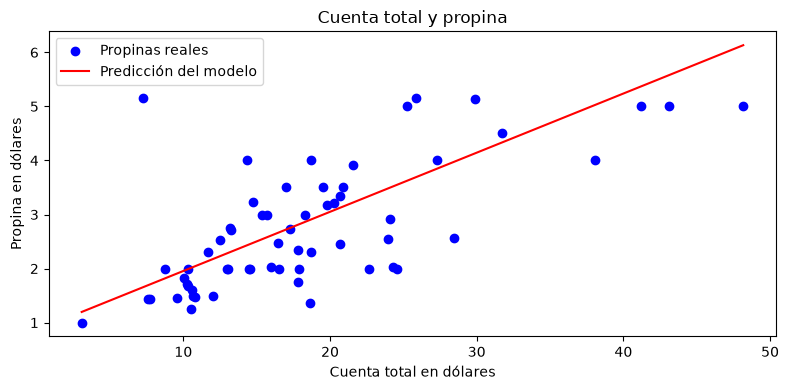

In [12]:
tabla_comparacion = pd.DataFrame({
    "Cuenta total": cuentas_prueba["total_bill"].to_numpy(),
    "Propina real": propinas_prueba.to_numpy(),
    "Propina estimada": propinas_estimadas
})

print("Primeros cinco resultados:")
display(tabla_comparacion.head())

# Ordenar las cuentas para dibujar la recta.
cuentas_ordenadas = cuentas_prueba.sort_values("total_bill")

propinas_de_la_recta = modelo_propinas.predict(cuentas_ordenadas)

# Crear el gráfico.
plt.figure(figsize=(8, 4))

plt.scatter(
    cuentas_prueba["total_bill"],
    propinas_prueba,
    color="blue",
    label="Propinas reales"
)

plt.plot(
    cuentas_ordenadas["total_bill"],
    propinas_de_la_recta,
    color="red",
    label="Predicción del modelo"
)

plt.xlabel("Cuenta total en dólares")
plt.ylabel("Propina en dólares")
plt.title("Cuenta total y propina")
plt.legend()
plt.tight_layout()
plt.show()

## 07 · Inspeccionar residuos
**Objetivo.** Calcular `real − predicho`; graficar los residuos contra las predicciones, con una línea horizontal en cero.

*Pista:* `.to_numpy()`, `plt.scatter()`, `plt.axhline(0)`.

**Resultado esperado:** Gráfico de residuos.

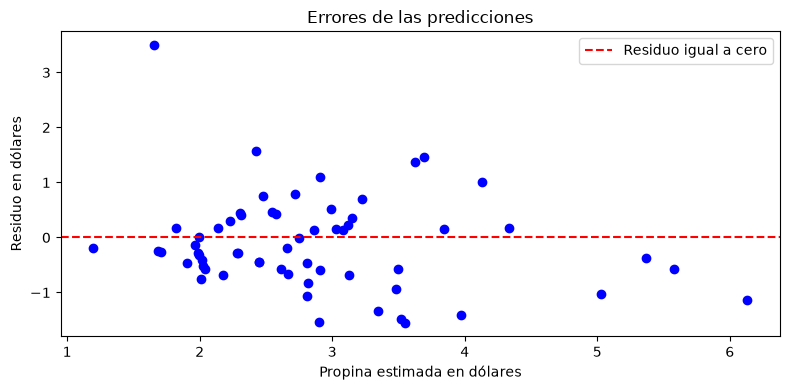

Residuo más bajo: -1.5477
Residuo más alto: 3.4951


In [13]:
residuos = propinas_prueba.to_numpy() - propinas_estimadas

plt.figure(figsize=(8, 4))

plt.scatter(
    propinas_estimadas,
    residuos,
    color="blue"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Residuo igual a cero"
)

plt.xlabel("Propina estimada en dólares")
plt.ylabel("Residuo en dólares")
plt.title("Errores de las predicciones")
plt.legend()
plt.tight_layout()
plt.show()

print("Residuo más bajo:", round(residuos.min(), 4))
print("Residuo más alto:", round(residuos.max(), 4))

## 08 · Comparar una y dos entradas
**Objetivo.** Entrenar un segundo modelo usando `total_bill` y `size` juntos. Comparar **MAE, RMSE y R²** con el modelo inicial.

*Pista:* Definir `X2` con dos columnas y repetir la partición con el mismo `random_state`.

**Resultado esperado:** Comparación numérica de ambos modelos.

In [15]:
cuentas_y_personas = datos[["total_bill", "size"]]

entradas_entrenamiento, entradas_prueba, propinas_entrenamiento_dos, propinas_prueba_dos = train_test_split(
    cuentas_y_personas,
    propinas,
    test_size=0.25,
    random_state=42
)

modelo_dos_entradas = LinearRegression()

modelo_dos_entradas.fit(
    entradas_entrenamiento,
    propinas_entrenamiento_dos
)

propinas_estimadas_dos = modelo_dos_entradas.predict(entradas_prueba)


error_absoluto_medio_dos = mean_absolute_error(
    propinas_prueba_dos,
    propinas_estimadas_dos
)

error_cuadratico_medio_dos = mean_squared_error(
    propinas_prueba_dos,
    propinas_estimadas_dos
)

raiz_error_cuadratico_dos = error_cuadratico_medio_dos ** 0.5

coeficiente_determinacion_dos = r2_score(
    propinas_prueba_dos,
    propinas_estimadas_dos
)

tabla_resultados = pd.DataFrame({
    "Modelo": [
        "Solo cuenta total",
        "Cuenta total y cantidad de personas"
    ],
    "MAE": [
        error_absoluto_medio,
        error_absoluto_medio_dos
    ],
    "RMSE": [
        raiz_error_cuadratico,
        raiz_error_cuadratico_dos
    ],
    "R²": [
        coeficiente_determinacion,
        coeficiente_determinacion_dos
    ]
})

display(tabla_resultados.round(4))

,Modelo,MAE,RMSE,R²
0,Solo cuenta total,0.6522,0.8631,0.4401
1,Cuenta total y cantidad de personas,0.6734,0.8799,0.4180


## Preguntas de desarrollo
Responder con los resultados obtenidos y, cuando corresponda, hacer referencia a los gráficos.

1. ¿Qué información contiene `X` y cuál es el objetivo `y`? ¿Qué cambia en la entrada cuando se agrega `size`?
2. ¿Cómo interpretar el MAE del primer modelo en **dólares de propina**? Dar un ejemplo de su significado.
3. ¿Qué diferencia existe entre MAE y RMSE? ¿Qué sugiere que RMSE sea mayor?
4. ¿Qué representa el R² obtenido? Explicar por qué **no** es un porcentaje de predicciones correctas.
5. ¿Qué se observa en el gráfico de residuos? ¿Hay valores especialmente alejados de cero?
6. ¿El modelo con dos entradas mejora los resultados en test? Justificar con MAE, RMSE y R² y proponer una explicación posible.

### Respuestas
**1.** `X` contiene la cuenta total y `y` contiene la propina real. Al agregar `size`, el modelo también utiliza la cantidad de personas para predecir la propina.

**2.** El MAE de 0,6522 USD indica que el modelo se equivoca aproximadamente 65 centavos en promedio. Por ejemplo, estimar 2,35 USD cuando la propina real es 3 USD genera un error de 0,65 USD.

**3.** El MAE promedia los errores absolutos, mientras que el RMSE da mayor peso a los errores grandes. El RMSE de 0,8631 USD, superior al MAE, refleja que los errores tienen distintas magnitudes y algunos son mayores.

**4.** El R² de 0,4401 indica que el modelo explica aproximadamente el 44 % de la variabilidad de las propinas en prueba. No representa un porcentaje de predicciones correctas, porque evalúa errores cuadrados y no cuenta aciertos.

**5.** El gráfico muestra residuos positivos y negativos alrededor de cero. Destacan valores de aproximadamente +3,50 USD y −1,55 USD, que corresponden a una subestimación y una sobreestimación, respectivamente.

**6.** El segundo modelo no mejora los resultados en prueba: el MAE aumenta de 0,6522 a 0,6734 USD, el RMSE sube de 0,8631 a 0,8799 USD y el R² baja de 0,4401 a 0,4180. Una posible explicación es que la cantidad de personas aporta poca información adicional a la cuenta total.